In [10]:
# System packages
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ara tesseract-ocr-fra poppler-utils libtesseract-dev

# Python packages
!pip install -q pytesseract pdf2image pymupdf Pillow opencv-python-headless matplotlib numpy

print("Installation complete.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 118250 files and directories currently installed.)
Preparing to unpack .../libarchive13_3.6.0-1ubuntu1.7_amd64.deb ...
Unpacking libarchive13:amd64 (3.6.0-1ubuntu1.7) over (3.6.0-1ubuntu1.6) ...
Selecting previously unselected package libarchive-dev:amd64.
Preparing to unpack .../libarchive-dev_3.6.0-1ubuntu1.7_amd64.deb ...
Unpacking libarchive-dev:amd64 (3.6.0-1ubuntu1.7) ...
Selecting previously unselected package libleptonica-dev.
Preparing to unpack .../libleptonica-dev_1.82.0-3build1_amd64.deb ...
Unpacking libleptonica-dev (1.82.0-3build1) ...
Selecting previously unselected package libtesseract-dev:amd64.
Preparing to unpack .../libtesseract-dev_4.1.1-2.1build1_amd64.deb ...
Unpacking libtesseract-dev:amd64 (4.1.1-2.1build1) ...
Setting up libarchive13:amd64 (3.6.0-1ubun

In [11]:
import pytesseract
from PIL import Image
import numpy as np
import cv2

print("Tesseract version:", pytesseract.get_tesseract_version())
print("Available languages:", pytesseract.get_languages())

# Quick test - OCR on a blank image to verify it works
test_img = Image.new('RGB', (100, 30), color='white')
try:
    text = pytesseract.image_to_string(test_img)
    print("Tesseract is working.")
except Exception as e:
    print("Error:", e)

Tesseract version: 4.1.1
Available languages: ['ara', 'eng', 'fra', 'osd']
Tesseract is working.


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
from google.colab import files
from pathlib import Path
import shutil

TEST_DIR = Path("/content/drive/MyDrive/Data Legal/test")
TEST_DIR.mkdir(exist_ok=True)

print("Upload your Moroccan legal PDFs (scanned or digital):")
print("Ideally: 1 clean digital, 1 scanned, 1 low-quality")
print()

# uploaded = files.upload()

# for filename, content in uploaded.items():
#     dest = TEST_DIR / filename
#     with open(dest, "wb") as f:
#         f.write(content)
#     print(f"Saved: {filename}")

pdf_files = sorted(TEST_DIR.glob("*.pdf"))
print(f"\nFiles ready: {len(pdf_files)}")

Upload your Moroccan legal PDFs (scanned or digital):
Ideally: 1 clean digital, 1 scanned, 1 low-quality


Files ready: 4


Converting: Livret 2.pdf
  2 pages extracted
Converting: code_route.pdf
  2 pages extracted
Converting: ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf
  2 pages extracted
Converting: مدونة الأسرة1.pdf
  2 pages extracted

Total pages: 8


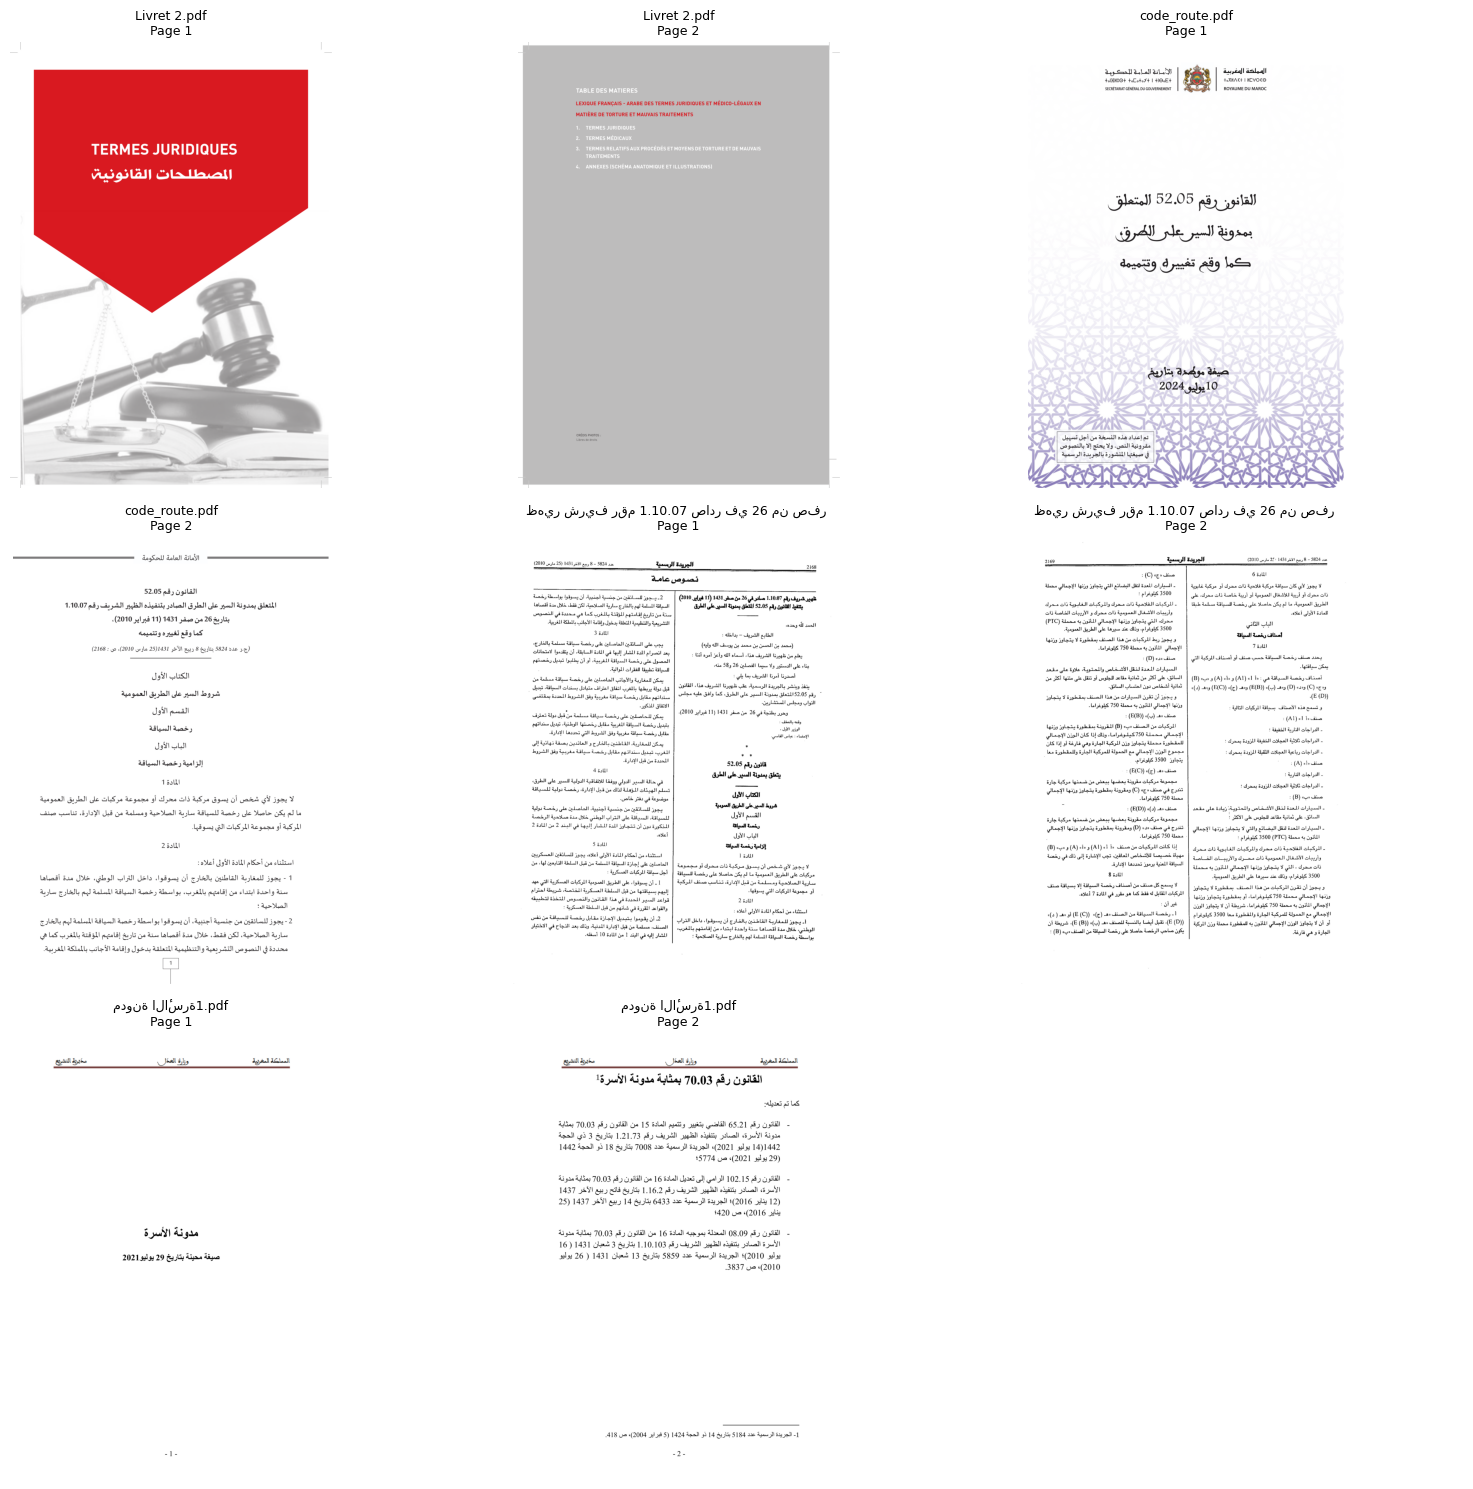

In [15]:
from pdf2image import convert_from_path
import matplotlib.pyplot as plt

# Take first 2 pages from each PDF
test_pages = []

for pdf_path in pdf_files:
    print(f"Converting: {pdf_path.name}")
    try:
        images = convert_from_path(pdf_path, dpi=300, first_page=1, last_page=2)
        for i, img in enumerate(images):
            test_pages.append({
                "source": pdf_path.name,
                "page_num": i + 1,
                "image": img,
            })
        print(f"  {len(images)} pages extracted")
    except Exception as e:
        print(f"  Error: {e}")

print(f"\nTotal pages: {len(test_pages)}")

# Show all pages
n = len(test_pages)
cols = min(n, 3)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 5*rows))
if rows == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, page in enumerate(test_pages):
    axes[i].imshow(page["image"])
    axes[i].set_title(f"{page['source'][:40]}\nPage {page['page_num']}", fontsize=9)
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

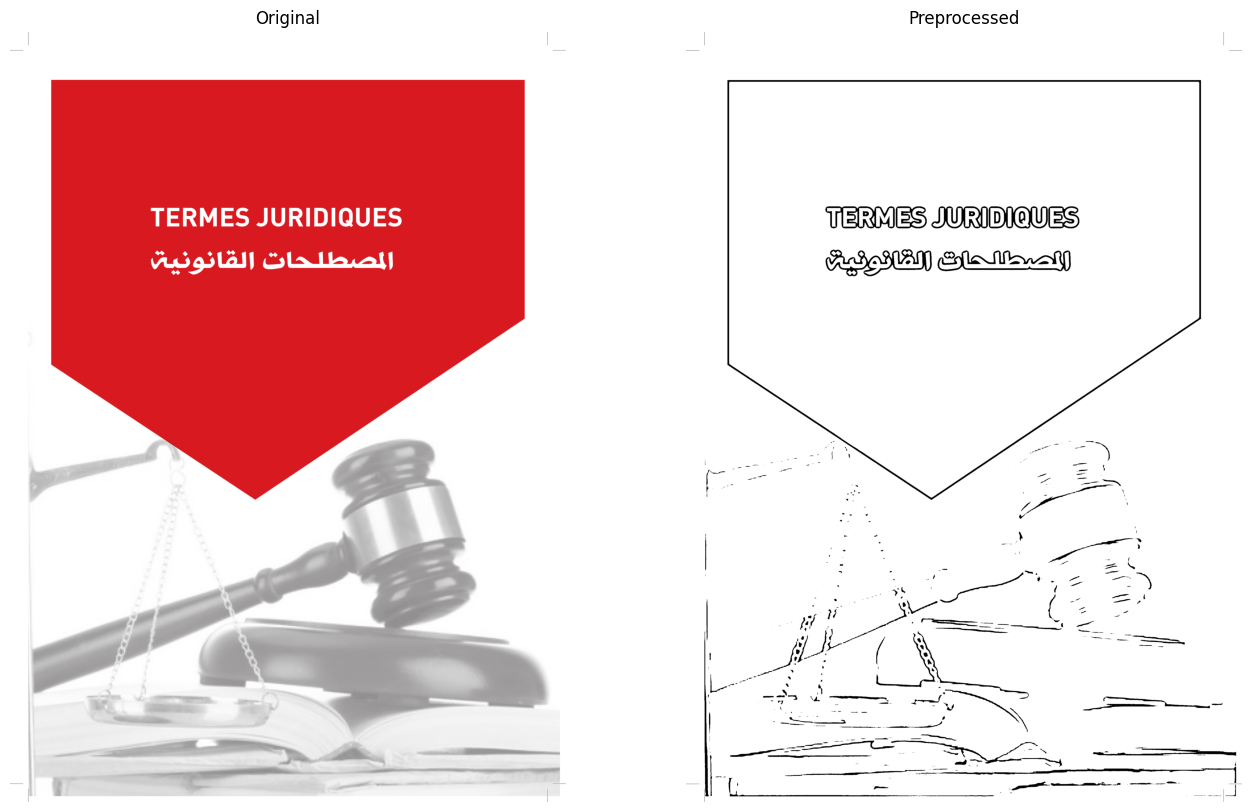

In [16]:
def preprocess_for_ocr(pil_image):
    """Optimize image for Arabic OCR."""
    # Convert to OpenCV
    img = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2GRAY)

    # Step 1: Denoise
    denoised = cv2.fastNlMeansDenoising(img, h=10)

    # Step 2: Enhance contrast
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(denoised)

    # Step 3: Binarize with adaptive threshold
    binary = cv2.adaptiveThreshold(
        enhanced, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31, 10
    )

    # Step 4: Remove small specks
    kernel = np.ones((2, 2), np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

    return Image.fromarray(cleaned)


# Test on first page
original = test_pages[0]["image"]
processed = preprocess_for_ocr(original)

# Side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 10))
ax1.imshow(original)
ax1.set_title("Original", fontsize=12)
ax1.axis('off')

ax2.imshow(processed, cmap='gray')
ax2.set_title("Preprocessed", fontsize=12)
ax2.axis('off')

plt.show()

In [17]:
import pytesseract
import time

# Best config for Arabic: OEM 3 (LSTM), PSM 6 (uniform block)
TESS_CONFIG = r'--oem 3 --psm 6 -l ara+fra'

print("Running optimized Tesseract OCR...")
print("=" * 60)

for i, page in enumerate(test_pages):
    # Apply preprocessing
    processed_img = preprocess_for_ocr(page["image"])

    # OCR
    start = time.time()
    text = pytesseract.image_to_string(processed_img, config=TESS_CONFIG)
    elapsed = time.time() - start

    # Store results
    page["ocr_text"] = text.strip()
    page["ocr_time"] = round(elapsed, 2)
    page["ocr_chars"] = len(text.strip())

    # Count Arabic vs French characters
    arabic = sum(1 for c in text if '\u0600' <= c <= '\u06ff')
    french = sum(1 for c in text if c.isascii() and c.isalpha())

    print(f"Page {i+1}: {page['source'][:50]} (p{page['page_num']})")
    print(f"  Time: {elapsed:.1f}s | Chars: {len(text.strip())} | Arabic: {arabic} | French: {french}")

    # Preview first 300 chars
    preview = text.strip()[:300].replace('\n', ' | ')
    print(f"  Text: {preview}")
    print()

print("=" * 60)
print("OCR complete.")

Running optimized Tesseract OCR...
Page 1: Livret 2.pdf (p1)
  Time: 6.8s | Chars: 223 | Arabic: 25 | French: 59
  Text: | | | TERMES JURIDIQUES | AIT ERNST | | Dee 2 0 TT LD | ‏الام‎ 2 FO = | | ‏ا ء‎ à 3 | : 2 à 7, TT | 0 0 3 LT 2 | ‏ا‎ 37 Lo) | LA CE T7 | 4 d « TT ‏ا‎ TE ‏امتح‎ | ‎AO Ÿ 5 | ! a : ١ 0 | ‏اث تسا‎ 7 | ï 7 0 0 + LL —- TK ‏سي سير‎ _ — | s — …. ‏سم‎ -__- i | a —

Page 2: Livret 2.pdf (p2)
  Time: 3.9s | Chars: 333 | Arabic: 10 | French: 257
  Text: VNAE OS ANS |  | LEXIQUE FRANCAIS - ARABE DES TERMES JURIDIQUES ET MÉDICO-LÉGAUX EN |  | MATIÈRE DE TORTURE ET MAUVAIS TRAITEMENTS |  | TRLE RME SYJURIDIQUES) |  | PBTERMESIMEDICAUX] |  | SATERMESRELATIES AUXIPROCEDES'ENMOYENS'DERORTURE!E D EIMAUVAIS) | ‏113:113ارالتطتارا‎ |  | ZANNEXESI(SCHEMAYANATOMIQUEIETTIITUSTRATIONS) |  | 

Page 3: code_route.pdf (p1)
  Time: 5.9s | Chars: 264 | Arabic: 99 | French: 62
  Text: القانوز رقم 32.05 المتعلق | كما وقع تغييرق وتتميمة | ‎OU OUEST‏ موس يت ريق ده ل د ا ل بار | را اه لبر 1 ال | ا | لح

Testing on: ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 ف (p1)
Original (no preprocessing):
  Chars: 3005 | Arabic: 2287 | Time: 31.9s

Adaptive Threshold:
  Chars: 3217 | Arabic: 2396 | Time: 29.5s

OTSU Binarization:
  Chars: 3108 | Arabic: 2340 | Time: 29.2s

Sharpen + OTSU:
  Chars: 3020 | Arabic: 2246 | Time: 27.0s



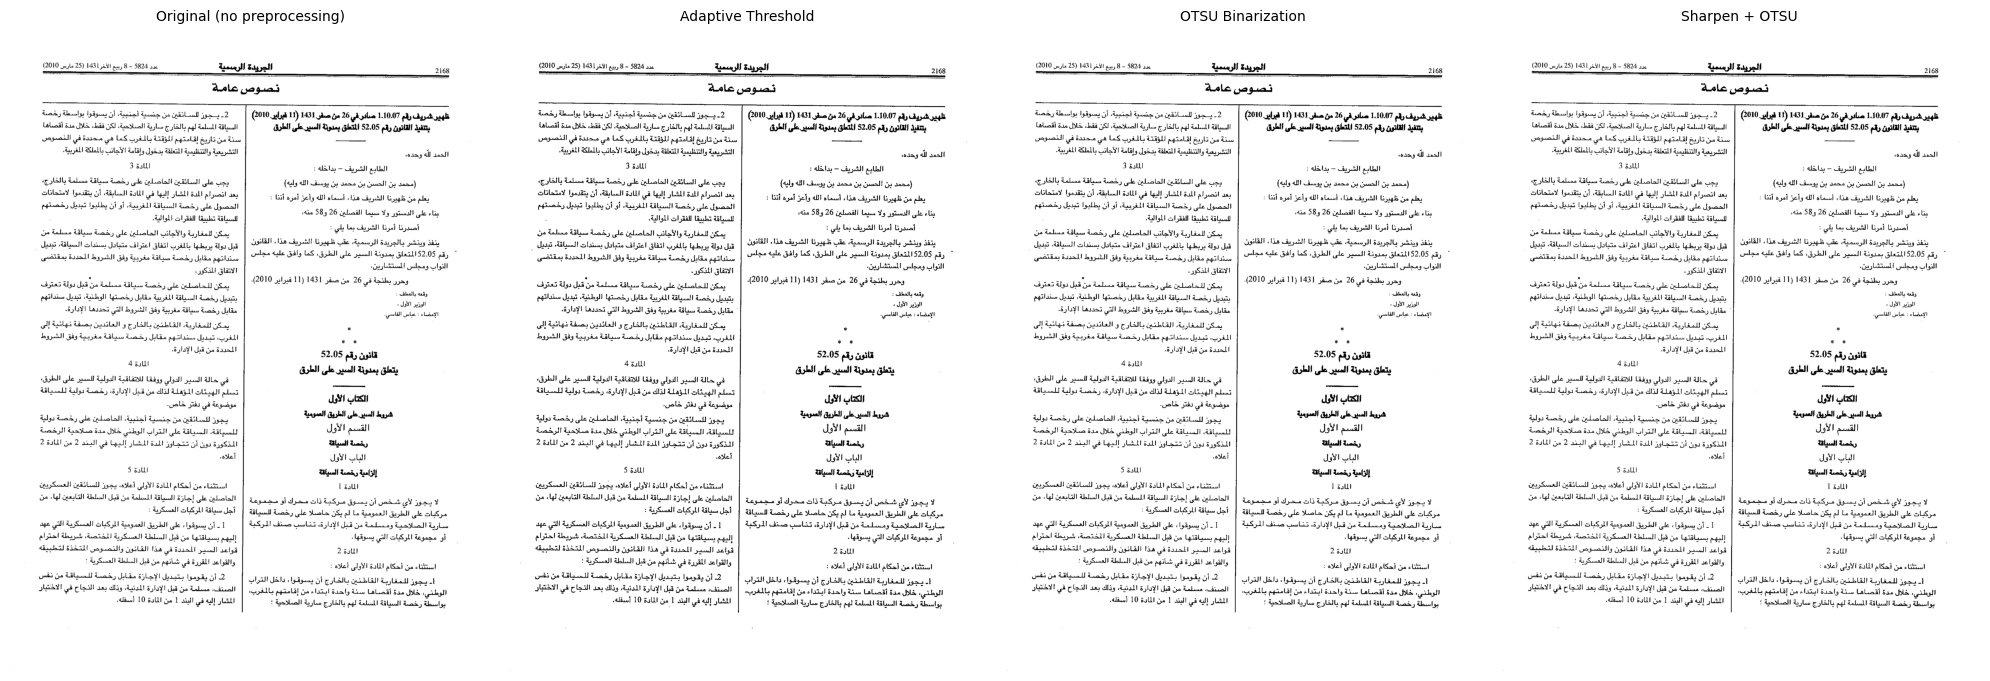

Best method: Adaptive Threshold (2396 Arabic chars)


In [18]:
def preprocess_variant_otsu(pil_image):
    """Alternative: OTSU binarization instead of adaptive."""
    img = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2GRAY)
    denoised = cv2.fastNlMeansDenoising(img, h=10)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    enhanced = clahe.apply(denoised)
    _, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return Image.fromarray(binary)


def preprocess_variant_sharp(pil_image):
    """Sharpen + binarize."""
    img = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2GRAY)
    kernel = np.array([[-1,-1,-1], [-1,9,-1], [-1,-1,-1]])
    sharpened = cv2.filter2D(img, -1, kernel)
    _, binary = cv2.threshold(sharpened, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return Image.fromarray(binary)


# Pick a page that has Arabic content (page 5 or 6)
test_img = test_pages[4]["image"]  # Page 5 - good Arabic output
print(f"Testing on: {test_pages[4]['source'][:50]} (p{test_pages[4]['page_num']})")

variants = {
    "Original (no preprocessing)": test_img,
    "Adaptive Threshold": preprocess_for_ocr(test_img),
    "OTSU Binarization": preprocess_variant_otsu(test_img),
    "Sharpen + OTSU": preprocess_variant_sharp(test_img),
}

results = {}

for name, img in variants.items():
    start = time.time()
    text = pytesseract.image_to_string(img, config=TESS_CONFIG)
    elapsed = time.time() - start

    arabic = sum(1 for c in text if '\u0600' <= c <= '\u06ff')
    french = sum(1 for c in text if c.isascii() and c.isalpha())

    results[name] = {
        "text": text.strip(),
        "chars": len(text.strip()),
        "arabic": arabic,
        "french": french,
        "time": round(elapsed, 2),
    }

    print(f"{name}:")
    print(f"  Chars: {len(text.strip())} | Arabic: {arabic} | Time: {elapsed:.1f}s")
    print()

# Show all variants side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 8))
for ax, (name, img) in zip(axes, variants.items()):
    ax.imshow(img, cmap='gray' if 'Original' not in name else None)
    ax.set_title(name, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Best method
best = max(results.items(), key=lambda r: r[1]["arabic"])
print(f"Best method: {best[0]} ({best[1]['arabic']} Arabic chars)")

In [19]:
import pytesseract
import time

TESS_CONFIG = r'--oem 3 --psm 6 -l ara+fra'

print("=" * 60)
print("FINAL OPTIMIZED TESSERACT PIPELINE")
print("Config: OEM 3, PSM 6, ara+fra")
print("Preprocessing: Adaptive Threshold")
print("=" * 60)
print()

final_results = []

for i, page in enumerate(test_pages):
    # Preprocess
    processed = preprocess_for_ocr(page["image"])

    # OCR
    start = time.time()
    text = pytesseract.image_to_string(processed, config=TESS_CONFIG)
    elapsed = time.time() - start

    # Metrics
    chars_total = len(text.strip())
    arabic = sum(1 for c in text if '\u0600' <= c <= '\u06ff')
    french = sum(1 for c in text if c.isascii() and c.isalpha())
    words = len(text.strip().split())

    # Quality score: Arabic density
    arabic_density = (arabic / chars_total * 100) if chars_total > 0 else 0

    final_results.append({
        "source": page["source"][:50],
        "page": page["page_num"],
        "chars": chars_total,
        "arabic": arabic,
        "french": french,
        "words": words,
        "arabic_density": round(arabic_density, 1),
        "time": round(elapsed, 1),
        "text": text.strip(),
    })

    quality = "GOOD" if arabic > 500 else "LOW" if arabic < 100 else "MODERATE"
    print(f"[{quality}] {page['source'][:40]} p{page['page_num']}")
    print(f"       Chars: {chars_total} | Arabic: {arabic} ({arabic_density:.0f}%) | Words: {words} | Time: {elapsed:.1f}s")
    print()

# Summary
total_arabic = sum(r["arabic"] for r in final_results)
total_chars = sum(r["chars"] for r in final_results)
total_time = sum(r["time"] for r in final_results)
good_pages = sum(1 for r in final_results if r["arabic"] > 500)

print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Pages processed: {len(final_results)}")
print(f"Good pages (>500 Arabic chars): {good_pages}")
print(f"Total Arabic characters: {total_arabic}")
print(f"Total characters: {total_chars}")
print(f"Overall Arabic density: {total_arabic/total_chars*100:.0f}%")
print(f"Total time: {total_time:.1f}s")
print(f"Average time per page: {total_time/len(final_results):.1f}s")

FINAL OPTIMIZED TESSERACT PIPELINE
Config: OEM 3, PSM 6, ara+fra
Preprocessing: Adaptive Threshold

[LOW] Livret 2.pdf p1
       Chars: 223 | Arabic: 25 (11%) | Words: 75 | Time: 6.3s

[LOW] Livret 2.pdf p2
       Chars: 333 | Arabic: 10 (3%) | Words: 35 | Time: 3.6s

[LOW] code_route.pdf p1
       Chars: 264 | Arabic: 99 (38%) | Words: 65 | Time: 5.7s

[GOOD] code_route.pdf p2
       Chars: 755 | Arabic: 567 (75%) | Words: 128 | Time: 4.7s

[GOOD] ظهير شريف رقم 1.10.07 صادر في 26 من صفر  p1
       Chars: 3217 | Arabic: 2396 (74%) | Words: 569 | Time: 29.6s

[GOOD] ظهير شريف رقم 1.10.07 صادر في 26 من صفر  p2
       Chars: 3139 | Arabic: 2174 (69%) | Words: 583 | Time: 28.1s

[LOW] مدونة الأسرة1.pdf p1
       Chars: 95 | Arabic: 69 (73%) | Words: 16 | Time: 1.0s

[GOOD] مدونة الأسرة1.pdf p2
       Chars: 913 | Arabic: 545 (60%) | Words: 161 | Time: 7.0s

SUMMARY
Pages processed: 8
Good pages (>500 Arabic chars): 4
Total Arabic characters: 5885
Total characters: 8939
Overall Arabic den